# Rice Blast Resistance GWAS — results walkthrough

This notebook **only reads the outputs** of the DVC pipeline (`dvc.yaml`, code in `scripts/`).
All computation lives in the pipeline so the tables and figures in `results/` are always the
ones the code produces. To regenerate everything:

```bash
bash scripts/tools/get_binaries.sh   # PLINK 1.90b7.2 + GEMMA 0.98.5 -> ./bin (Linux/WSL/Colab)
dvc pull                             # raw genotype, phenotype PDF, annotation (DagsHub remote)
dvc repro                            # parse_pheno -> qc -> dedup -> pca -> gemma -> summarize -> plots -> gene_mapping
```

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "dvc.yaml").exists() else Path.cwd().parent
TABLES, FIGS = ROOT / "results" / "tables", ROOT / "results" / "figures"
pd.set_option("display.max_colwidth", None)  # never truncate annotations


def show(name, width):
    """Embed a figure downsized to its display width (keeps the notebook small;
    full 300-dpi PNGs stay in results/figures/)."""
    import io
    from PIL import Image as PILImage
    im = PILImage.open(FIGS / name)
    im.thumbnail((width * 2, width * 20))  # 2x for sharp display on high-dpi screens
    buf = io.BytesIO()
    im.save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue(), width=width))


## 1. Sample flow (parsing → QC → de-duplication)

In [2]:
metrics = json.loads((ROOT / "results" / "metrics.json").read_text())
print(json.dumps({k: metrics[k] for k in ["phenotypes", "qc", "dedup", "pca"]}, indent=2))

{
  "phenotypes": {
    "pdf_pages": 13,
    "parsed": 314,
    "D41-2": 304,
    "12YL": 228,
    "genotyped": 413,
    "matched": 314
  },
  "qc": {
    "snps_in": 36901,
    "accessions_in": 413,
    "snps_pass": 30122,
    "accessions_pass": 383
  },
  "dedup": {
    "pairs_total": 73153,
    "pairs_pi_hat_ge_0.99": 2960,
    "pairs_pi_hat_ge_0.5": 2960,
    "dst_threshold": 0.99,
    "pairs_dst_ge_threshold": 56,
    "pairs_dst_both_phenotyped": 31,
    "clusters": 18,
    "accessions_in_clusters": 41,
    "removed": 23,
    "phenotyped_after_qc": 290,
    "accessions_after_dedup": 360,
    "phenotyped_after_dedup": 267
  },
  "pca": {
    "ld_pruned_snps": 1314,
    "accessions": 360,
    "pct_of_computed": [
      40.71,
      19.09,
      11.88,
      6.77,
      5.05,
      4.91,
      4.02,
      2.87,
      2.49,
      2.21
    ]
  }
}


Near-duplicate clusters (identity-by-state DST ≥ threshold; one accession kept per cluster):

In [3]:
pd.read_csv(TABLES / "duplicate_clusters.csv")

,cluster,NSFTV_ID,Name,Country,Subgroup,F_MISS,kept
0,1,1,Agostano,Italy,TEJ,0.008366,False
1,1,263,Maratelli,Italy,TEJ,0.005146,True
2,2,24,Carolina Gold,United States,TRJ,0.002257,True
3,2,26,Carolina Gold Sel,United States,TRJ,0.002789,False
4,2,65,Honduras,Honduras,TRJ,0.003519,False
5,2,229,Niquen,Chile,TRJ,0.002955,False
6,2,375,Upland,PONAPE ISLAND,TRJ,0.002888,False
7,3,25,Carolina Gold,United States,TRJ,0.004714,True
8,3,185,British Honduras Creole,Belize,TRJ,0.023770,False
9,4,27,NSF-TV 27,Pakistan,TRJ,0.004548,True


## 2. Population structure

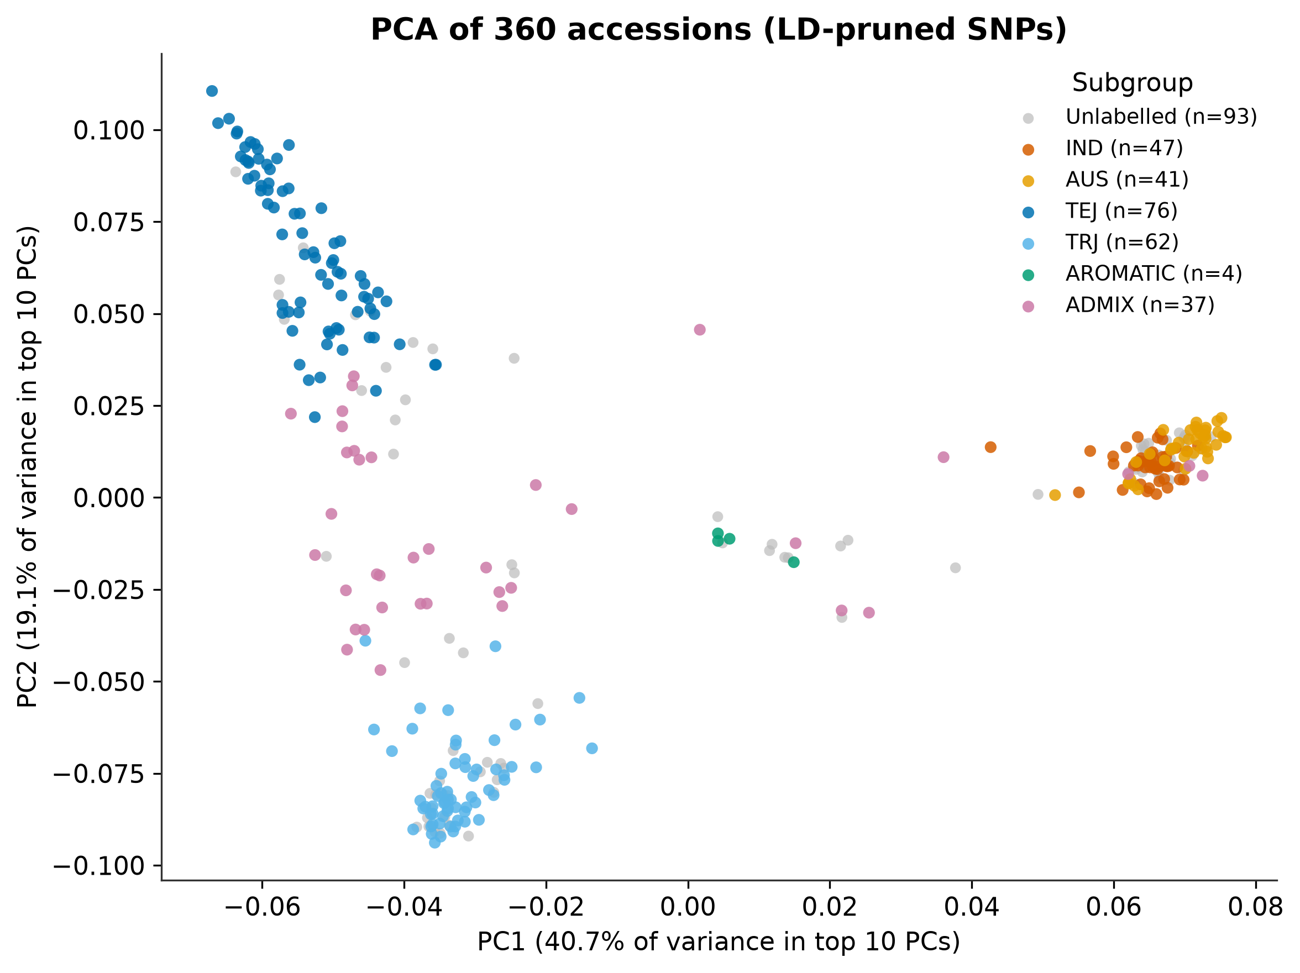

In [4]:
show("pca_subpopulation.png", 650)

## 3. Association results (GEMMA LMM, kinship + PCs)

In [5]:
pd.read_csv(TABLES / "gwas_run_summary.csv")

,trait_id,isolate,trait,n,n_snps_tested,PVE,PVE_SE,lambda_GC,top_p,bonferroni_p,suggestive_p,n_bonferroni_snps,n_suggestive_or_better_snps,significance
0,D41-2_LT,D41-2,Lesion Type,257,26059,0.748,0.086,0.994,1.610000e-05,0.000002,0.000038,0,6,suggestive only
1,D41-2_DLA,D41-2,Diseased Leaf Area,257,26059,0.342,0.173,0.892,1.340000e-06,0.000002,0.000038,1,6,Bonferroni
2,12YL_LT,12YL-DL-3-2,Lesion Type,193,26203,0.882,0.062,0.911,3.560000e-07,0.000002,0.000038,9,19,Bonferroni
3,12YL_DLA,12YL-DL-3-2,Diseased Leaf Area,193,26203,0.295,0.195,0.890,1.010000e-04,0.000002,0.000038,0,0,no association


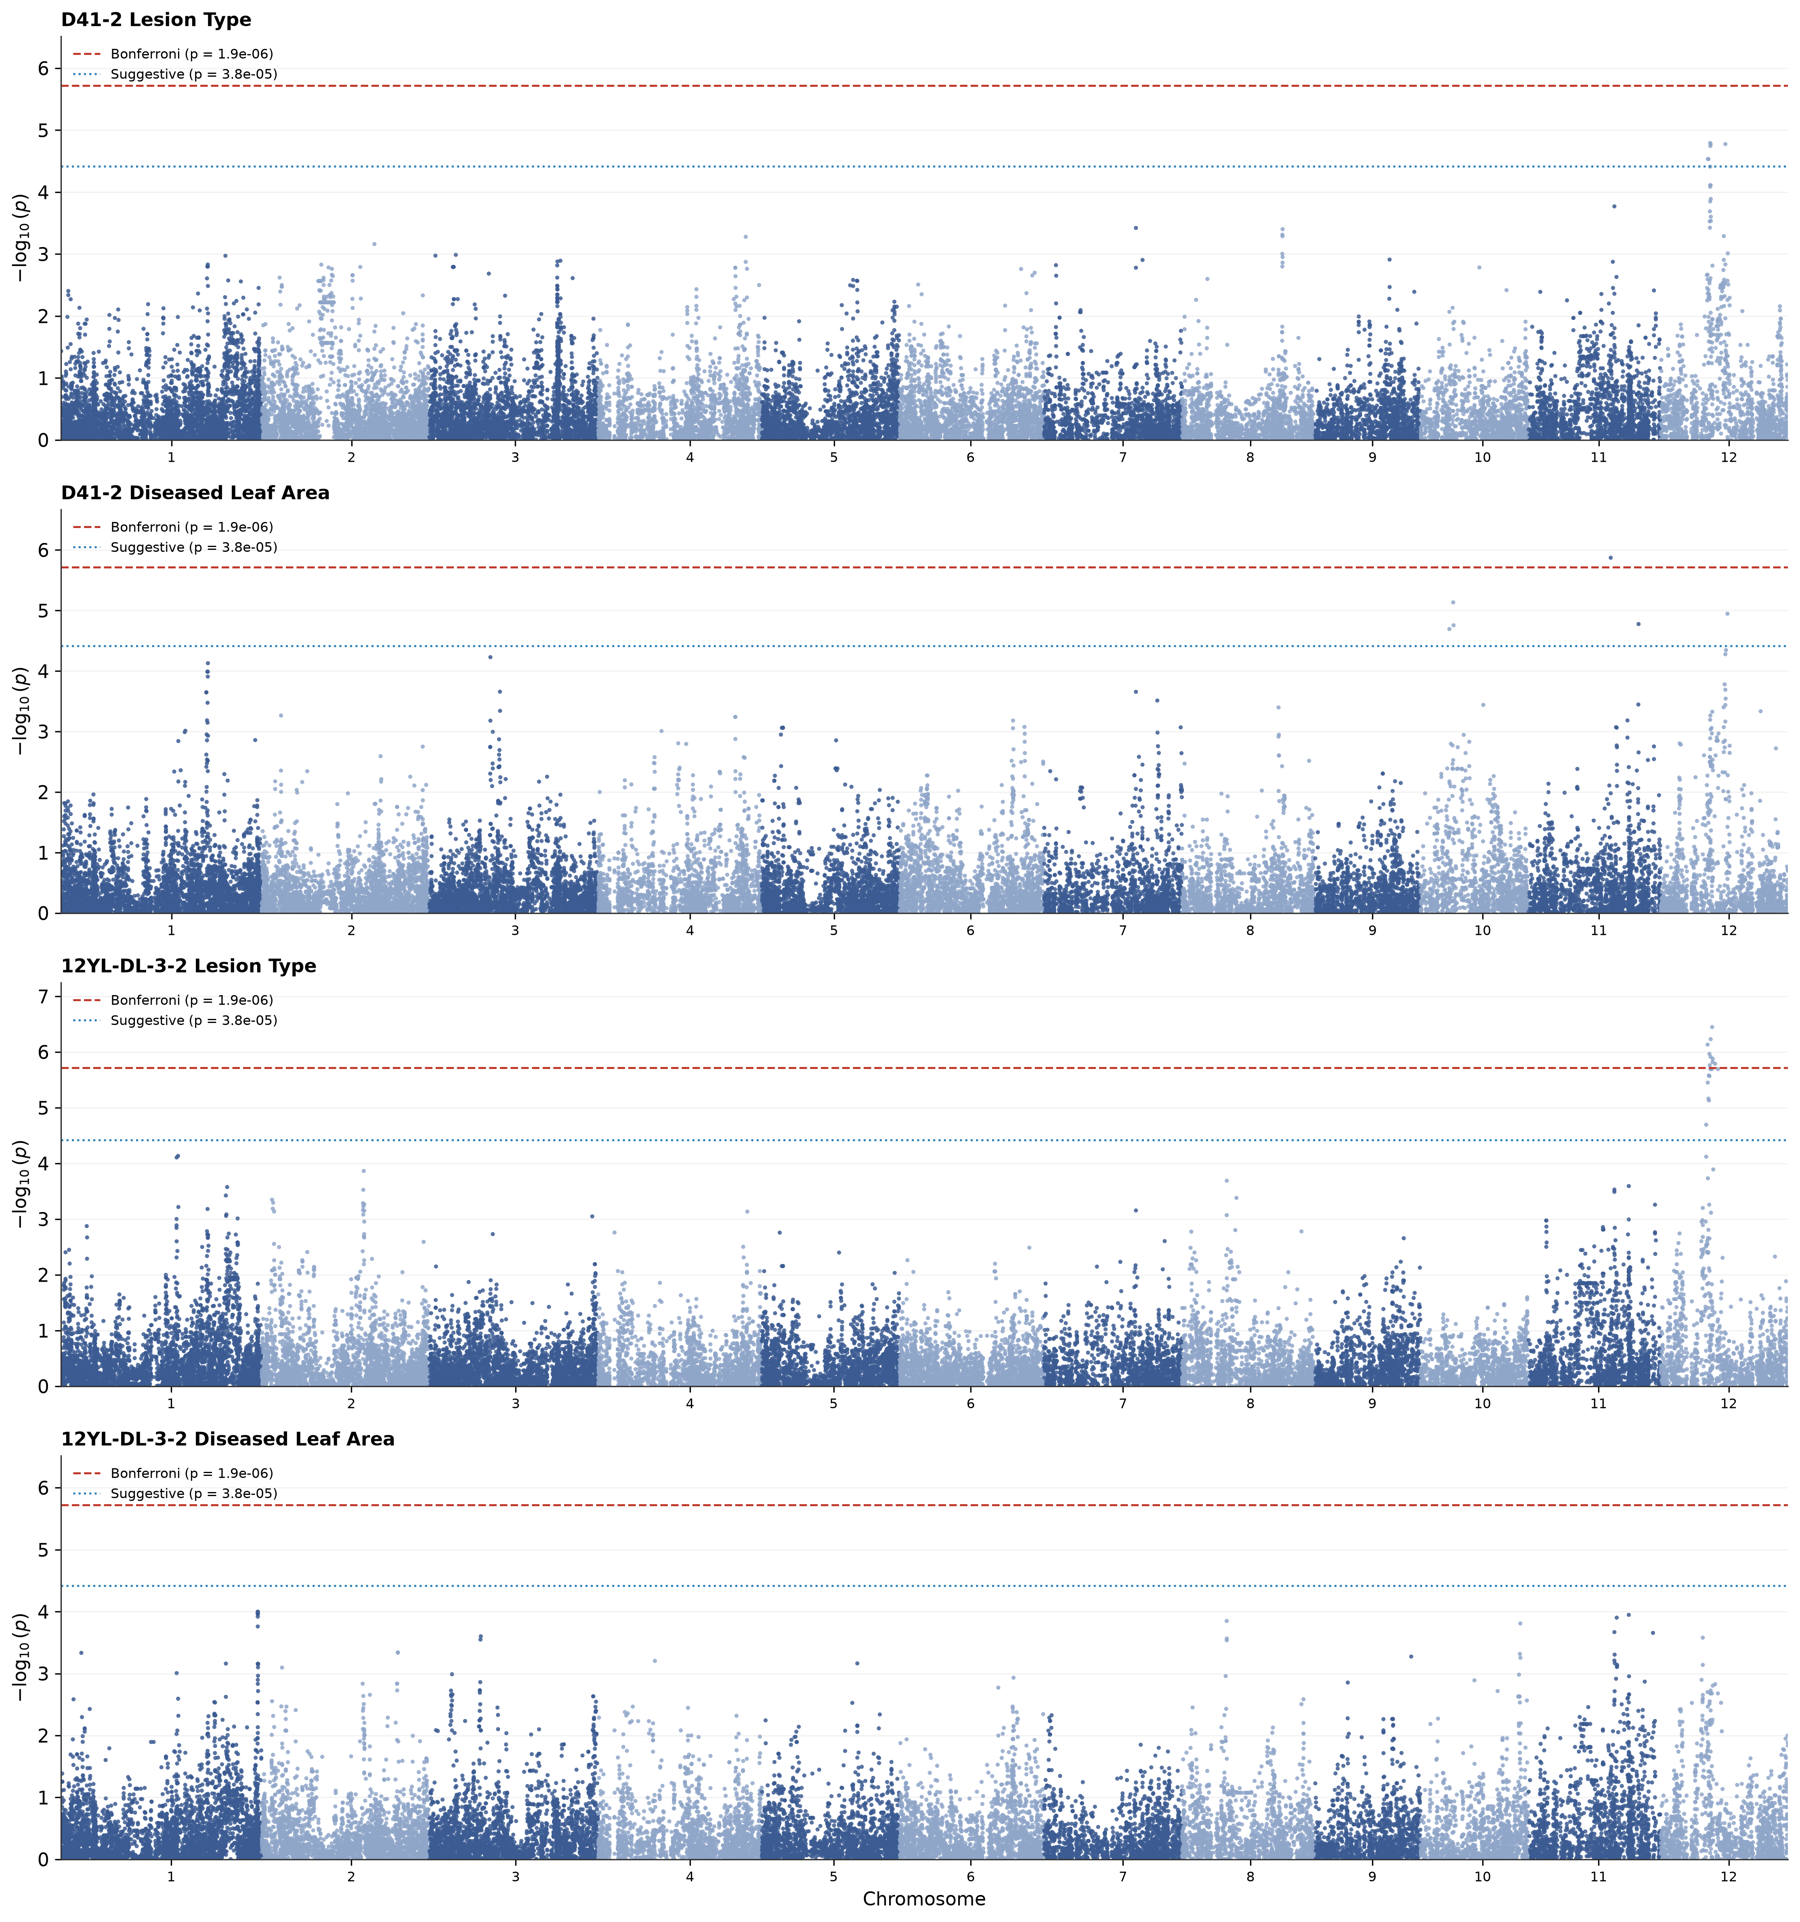

In [6]:
show("manhattan_all_traits_panel.png", 900)

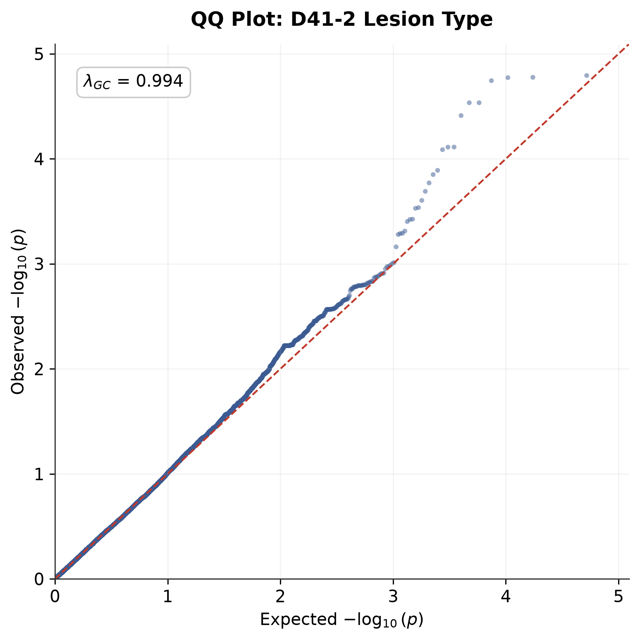

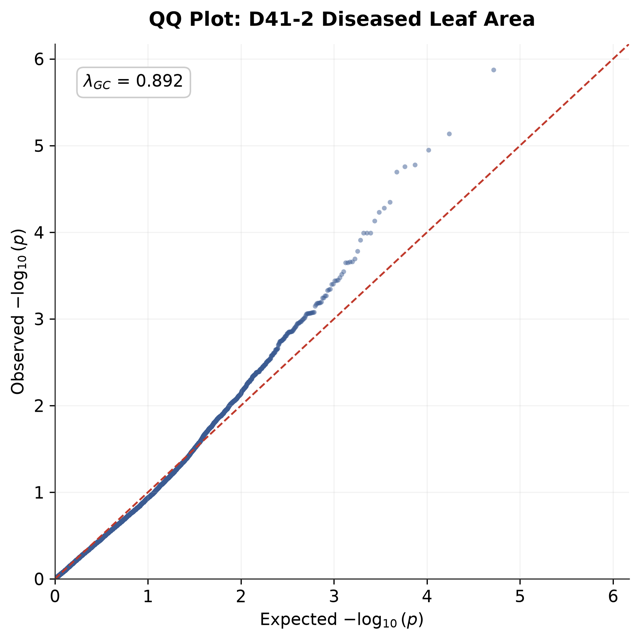

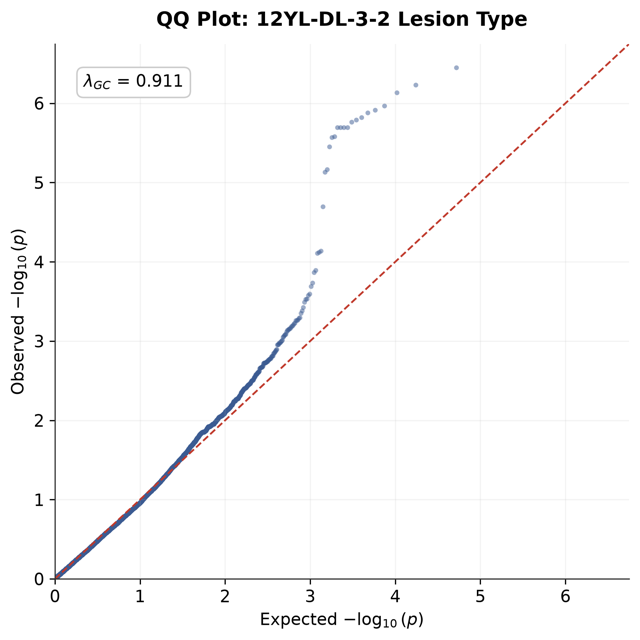

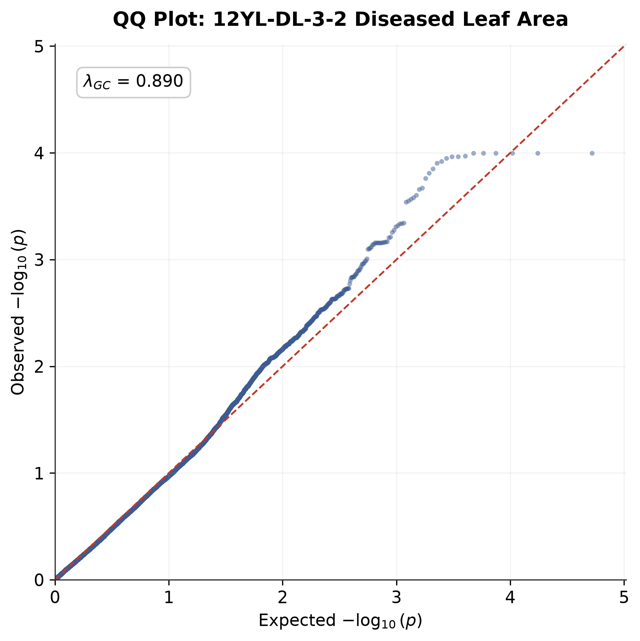

In [7]:
for slug in ["d41_2_LT", "d41_2_DLA", "12yl_LT", "12yl_DLA"]:
    show(f"qq_{slug}.png", 320)

In [8]:
pd.read_csv(TABLES / "suggestive_hits_all_traits.csv")

,trait,chr,rs,ps,allele1,allele0,af,beta,se,p_wald,bonferroni
0,D41-2_DLA,10,id10001923,6231500,C,G,0.367,-3.419638,0.787093,2.024029e-05,False
1,D41-2_DLA,10,id10002284,7044997,A,G,0.375,-3.675685,0.802687,7.339002e-06,False
2,D41-2_DLA,10,id10002294,7134484,T,C,0.368,-3.490267,0.797184,1.754721e-05,False
3,D41-2_DLA,11,id11006398,17823963,A,C,0.176,4.516635,0.911951,1.342216e-06,True
4,D41-2_DLA,11,id11009412,23814347,T,C,0.273,4.378619,0.997573,1.674098e-05,False
5,12YL_LT,12,id12003875,9906982,T,C,0.109,-1.613688,0.368961,2.021835e-05,False
6,12YL_LT,12,id12003973,10208157,T,C,0.109,-1.781316,0.347619,7.373310e-07,True
7,12YL_LT,12,ud12000654,10245978,A,C,0.116,-1.669482,0.349359,3.546864e-06,False
8,D41-2_LT,12,id12003996,10276913,T,C,0.222,-0.919286,0.215948,2.925834e-05,False
9,12YL_LT,12,id12004003,10385086,A,T,0.171,-1.644659,0.355383,6.870038e-06,False


## 4. Candidate genes and the Pita / Ptr validation checkpoint
SNP positions are lifted from MSU6 to MSU7 before mapping to MSU7 gene models.

In [9]:
pd.read_csv(TABLES / "top_candidate_genes.csv")

,gene_id,chr,gene_start,gene_end,best_p,best_snp,min_distance_bp,n_hit_snps,traits,annotation,known_gene,confidence
0,LOC_Os12g19304,12,11193846,11205134,3.565000e-07,id12004284,939,1,12YL_LT,"Fe-S metabolism associated domain containing protein, expressed",NaN,candidate
1,LOC_Os12g18729,12,10822534,10833768,5.894000e-07,id12004230,20485,8,12YL_LT;D41-2_LT,expressed protein,Ptr/Pita2,known R gene
2,LOC_Os12g18770,12,10862289,10872221,5.894000e-07,id12004230,0,5,12YL_LT;D41-2_LT,"oxysterol-binding protein, putative, expressed",NaN,candidate
3,LOC_Os12g17830,12,10207858,10211169,7.373000e-07,id12003973,0,1,12YL_LT,expressed protein,NaN,candidate
4,LOC_Os12g18360,12,10606359,10612068,1.082000e-06,id12004093,0,7,12YL_LT;D41-2_LT,"NB-ARC domain containing protein, expressed",Pita,known R gene
5,LOC_Os12g19470,12,11320267,11322547,1.323000e-06,ud12000700,0,1,12YL_LT,"ribulose bisphosphate carboxylase small chain, chloroplast precursor, putative, expressed",NaN,candidate
6,LOC_Os11g31330,11,18288357,18290726,1.342000e-06,id11006398,0,1,D41-2_DLA,"no apical meristem protein, putative, expressed",NaN,candidate
7,LOC_Os12g19381,12,11262563,11278448,1.515000e-06,id12004315,0,1,12YL_LT,"ribulose bisphosphate carboxylase small chain, chloroplast precursor, putative, expressed",NaN,candidate
8,LOC_Os12g20280,12,11843818,11845360,1.628000e-06,id12004405,977,1,12YL_LT,expressed protein,NaN,candidate
9,LOC_Os12g18450,12,10669458,10671969,1.731000e-06,id12004118,0,1,12YL_LT,expressed protein,NaN,candidate


In [10]:
pd.read_csv(TABLES / "validation_pita_ptr_hits.csv")

,known_gene,gene_id,gene_start,gene_end,trait,chr,rs,snp_pos_msu6,snp_pos_msu7,p_wald,distance_bp,lead_snp,r2_with_lead,annotation
0,Pita,LOC_Os12g18360,10606359,10612068,12YL_LT,12,id12004093,10604192,10606779,1.082417e-06,0,id12004284,1.000,"NB-ARC domain containing protein, expressed"
1,Pita,LOC_Os12g18360,10606359,10612068,12YL_LT,12,fd2,10604967,10607554,2.706870e-06,0,id12004284,0.942,"NB-ARC domain containing protein, expressed"
2,Pita,LOC_Os12g18360,10606359,10612068,12YL_LT,12,id12004118,10668612,10671199,1.731376e-06,59131,id12004284,0.942,"NB-ARC domain containing protein, expressed"
3,Pita,LOC_Os12g18360,10606359,10612068,12YL_LT,12,id12004075,10507291,10509878,7.413696e-06,96481,id12004284,0.480,"NB-ARC domain containing protein, expressed"
4,Pita,LOC_Os12g18360,10606359,10612068,12YL_LT,12,id12004058,10468515,10471102,2.638819e-06,135257,id12004284,0.480,"NB-ARC domain containing protein, expressed"
5,Pita,LOC_Os12g18360,10606359,10612068,D41-2_LT,12,id12004143,10761575,10764209,1.609731e-05,152141,id12004143,1.000,"NB-ARC domain containing protein, expressed"
6,Pita,LOC_Os12g18360,10606359,10612068,D41-2_LT,12,id12004183,10799415,10802049,1.802962e-05,189981,id12004143,0.603,"NB-ARC domain containing protein, expressed"
7,Ptr/Pita2,LOC_Os12g18729,10822534,10833768,D41-2_LT,12,id12004183,10799415,10802049,1.802962e-05,20485,id12004143,0.603,expressed protein
8,Ptr/Pita2,LOC_Os12g18729,10822534,10833768,12YL_LT,12,id12004211,10859755,10862389,2.028347e-06,28621,id12004284,1.000,expressed protein
9,Ptr/Pita2,LOC_Os12g18729,10822534,10833768,12YL_LT,12,id12004214,10860308,10862942,1.223321e-06,29174,id12004284,1.000,expressed protein


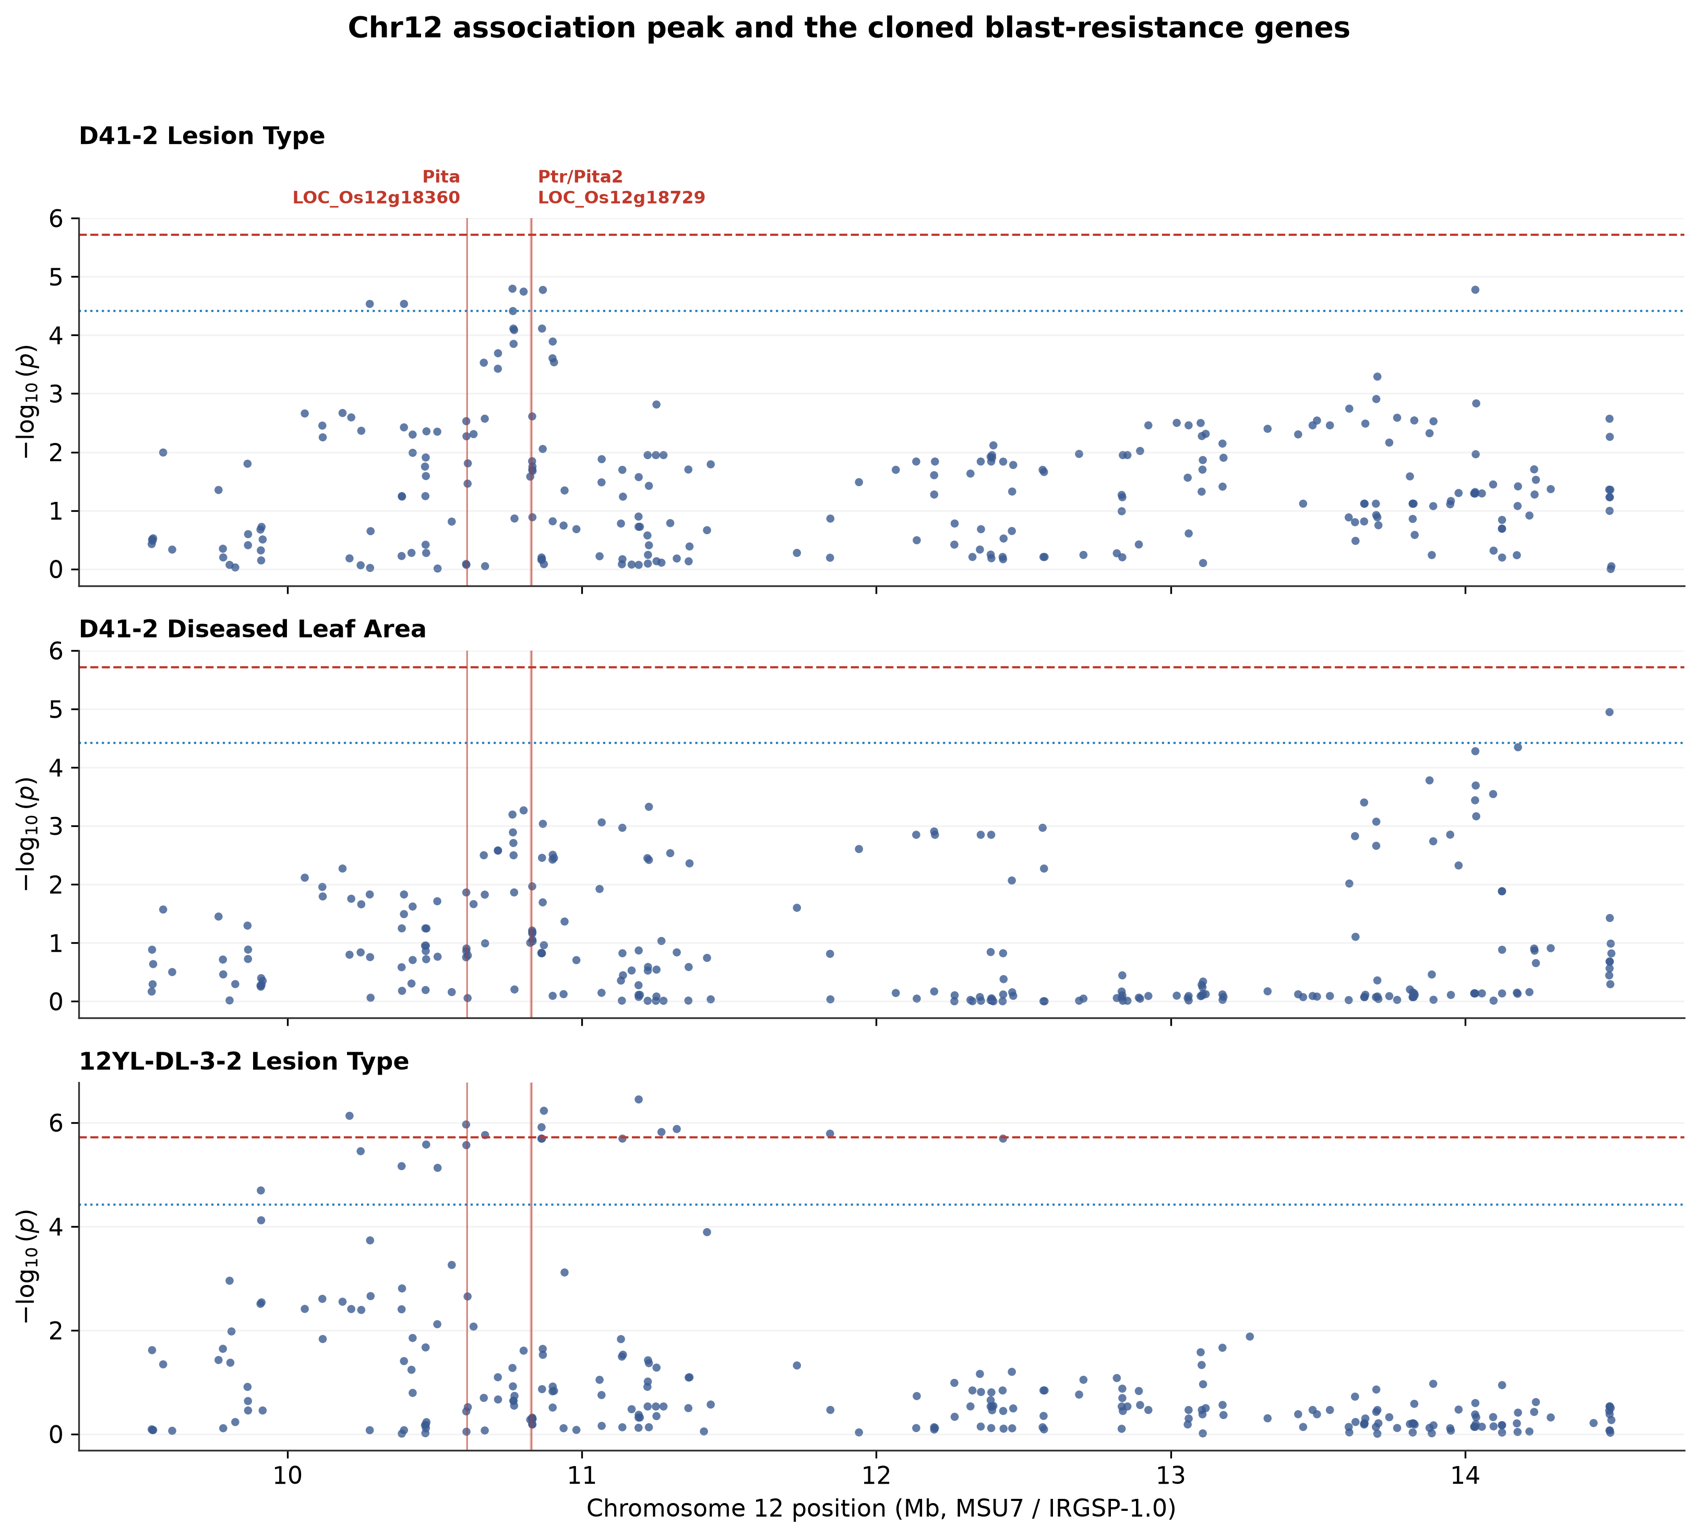

In [11]:
show("candidate_genes_chr12.png", 850)